# Análisis exploratorio — AI Text Detection Pile
Exploración del dataset original con Spark: tamaño, clases, longitudes, fuentes y artefactos.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.insert(0, "..")        

import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from src.config import get_spark, RAW_DIR
from src.data import load_raw, add_subsource

spark = get_spark("eda")
df = load_raw(spark)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/12 20:58:09 WARN Utils: Your hostname, MacBook-Air-de-alicia.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.17 instead (on interface en0)
26/10/12 20:58:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/12 20:58:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


***Esquema y tamaño***

Spark ha dividido el dataset en 16 trozos, y cada trozo lo procesa una tarea en paralelo.

In [3]:
df.printSchema()
print(f"Número de textos: {df.count():,}")
print(f"Particiones: {df.rdd.getNumPartitions()}")

root
 |-- source: string (nullable = true)
 |-- id: long (nullable = true)
 |-- text: string (nullable = true)

Número de textos: 1,392,522
Particiones: 16


## 1. Distribución de clases

***Clases en total y por fichero***

In [4]:
# Total por clase
clases = df.groupBy("source").count().collect()
total = sum(r["count"] for r in clases)
for r in clases:
    print(f"{r['source']:>6}: {r['count']:>9,}  ({r['count'] / total:.1%})")

# Contenido de cada fichero
fichero = F.element_at(F.split(F.input_file_name(), "/"), -1)
df.groupBy(fichero.alias("fichero"), "source").count().orderBy("fichero").show(truncate=False)

 human: 1,028,146  (73.8%)
    ai:   364,376  (26.2%)
+---------------------------------------------+------+------+
|fichero                                      |source|count |
+---------------------------------------------+------+------+
|train-00000-of-00007-bc5952582e004d67.parquet|human |198932|
|train-00001-of-00007-71c80017bc45f30d.parquet|human |198932|
|train-00002-of-00007-ee2d43f396e78fbc.parquet|human |198932|
|train-00003-of-00007-529931154b42b51d.parquet|human |198932|
|train-00004-of-00007-b269dc49374a2c0b.parquet|human |198932|
|train-00005-of-00007-3dce5e05ddbad789.parquet|ai    |165445|
|train-00005-of-00007-3dce5e05ddbad789.parquet|human |33486 |
|train-00006-of-00007-3d8a471ba0cf1c8d.parquet|ai    |198931|
+---------------------------------------------+------+------+



***Gráfico***

Ojo! Nunca hacer `toPandas()`del dataset entero, porque saturaría el driver. En este caso `clases`son solo dos filas, por eso se hace.

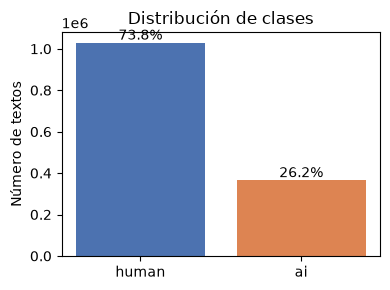

In [5]:
fuentes = [r["source"] for r in clases]
counts = [r["count"] for r in clases]

plt.figure(figsize=(4, 3))
plt.bar(fuentes, counts, color=["#4C72B0", "#DD8452"])
plt.ylabel("Número de textos")
plt.title("Distribución de clases")
for i, n in enumerate(counts):
    plt.text(i, n, f"{n / total:.1%}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 2. Fuentes de origen

El dataset no indica de qué fuente procede cada texto, solo si es humano o IA. Sin embargo, su
[ficha en Hugging Face](https://huggingface.co/datasets/artem9k/ai-text-detection-pile) declara
que se construyó combinando varias fuentes:

| Clase | Fuente declarada | Textos |
|---|---|---|
| Humano | Reddit WritingPrompts | 570k |
| Humano | OpenAI WebText | 260k |
| Humano | HC3 (respuestas humanas) | 58k |
| Humano | IvyPanda essays | sin especificar |
| IA | GPT-2 (gpt2-output-dataset) | 260k |
| IA | GPT-3 (davinci, dos conjuntos) | 74k |
| IA | GPT-J | 44k |
| IA | ChatGPT (HC3, Twitter, prompts) | 32,5k |

A continuación se comprueba si es posible identificar estas fuentes en los datos.

***id ordenados por clase***


In [6]:
df.groupBy("source").agg(
    F.min("id").alias("id_min"), F.max("id").alias("id_max"), F.count("*").alias("n")
).show()

+------+-------+-------+-------+
|source| id_min| id_max|      n|
+------+-------+-------+-------+
| human|      0|1048107|1028146|
|    ai|1048108|1418655| 364376|
+------+-------+-------+-------+



Estos resultados nos dan la pista de que el dataset se construyó concatenando fuentes en orden.

***Perfil de los textos a lo largo del id***

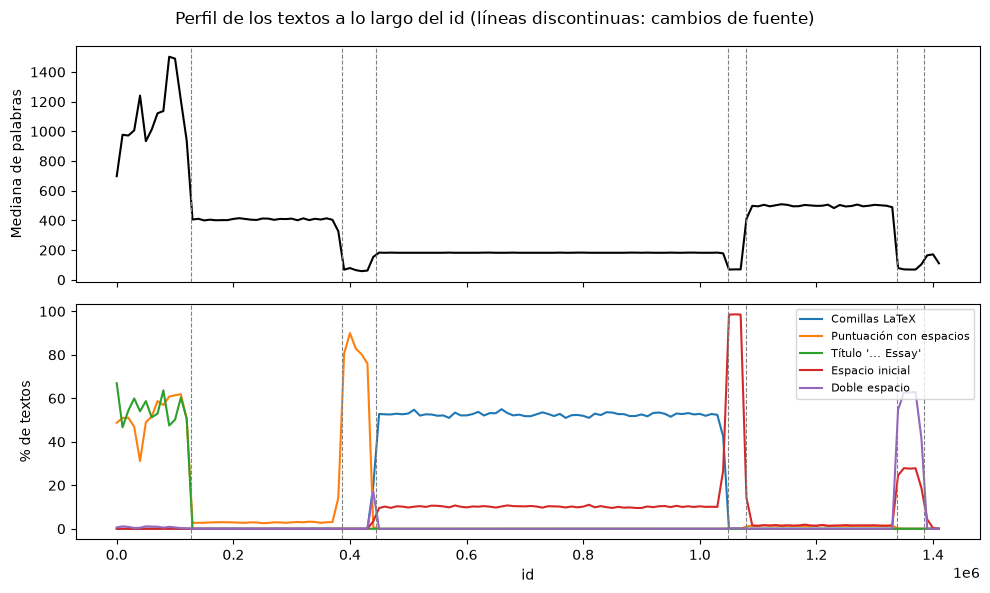

In [7]:
BIN_ID = 10_000
t = F.col("text")
perfil = (df
    .withColumn("tramo", F.floor(F.col("id") / BIN_ID) * BIN_ID)
    .groupBy("tramo").agg(
        F.percentile_approx(F.size(F.split(F.trim(t), r"\s+")), 0.5).alias("mediana_palabras"),
        F.avg(t.contains("``").cast("int")).alias("Comillas LaTeX"),
        F.avg(t.rlike(r"\w \. \w").cast("int")).alias("Puntuación con espacios"),
        F.avg(F.split(t, "\n").getItem(0).rlike(r"Essay\s*$").cast("int")).alias("Título '... Essay'"),
        F.avg(t.rlike(r"^\s").cast("int")).alias("Espacio inicial"),
        F.avg(t.rlike(r"[.!?]  [A-Z]").cast("int")).alias("Doble espacio"),
    )
    .orderBy("tramo")
    .collect())

LIMITES = [127_500, 387_000, 444_000, 1_048_100, 1_080_000, 1_338_000, 1_385_000]
x = [r["tramo"] for r in perfil]
artefactos = ["Comillas LaTeX", "Puntuación con espacios", "Título '... Essay'", "Espacio inicial", "Doble espacio"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(x, [r["mediana_palabras"] for r in perfil], color="black")
ax1.set_ylabel("Mediana de palabras")
for a in artefactos:
    ax2.plot(x, [r[a] * 100 for r in perfil], label=a)
ax2.set_ylabel("% de textos")
ax2.set_xlabel("id")
ax2.legend(fontsize=8, loc="upper right")
for ax in (ax1, ax2):
    for l in LIMITES:
        ax.axvline(l, color="grey", linestyle="--", linewidth=0.8)
fig.suptitle("Perfil de los textos a lo largo del id (líneas discontinuas: cambios de fuente)")
plt.tight_layout()
plt.show()

El gráfico muestra 8 bloques nítidos. La longitud y los artefactos cambian de golpe, y casi siempre justo en las líneas discontinuas.

***Tamaño de cada bloque frente a la ficha***

In [8]:
df_sub = add_subsource(df)
df_sub.groupBy("subsource").count().orderBy("subsource").show()

+---------------+------+
|      subsource| count|
+---------------+------+
|     ai_chatgpt| 26496|
|        ai_gpt2|258000|
|        ai_gpt3| 33392|
|        ai_gptj| 46488|
|      human_hc3| 43610|
| human_ivypanda|127500|
|human_reddit_wp|597536|
|  human_webtext|259500|
+---------------+------+



Varios tamaños coinciden con la ficha: WebText 259,5k (la ficha dice 260k), GPT-2 258k (260k), Reddit 598k (570k). IvyPanda tiene 127,5k, y la ficha no da cifra.

***Ejemplos de cada bloque***

In [9]:
for sub in ["human_ivypanda", "human_webtext", "human_hc3", "human_reddit_wp",
            "ai_instruct", "ai_gpt2", "ai_gptj_synth", "ai_chatgpt"]:
    print(f"\n=== {sub} ===")
    for r in df_sub.filter(F.col("subsource") == sub).limit(2).collect():
        print("  >>", repr(r["text"][:180]))


=== human_ivypanda ===


  >> '12 Years a Slave: An Analysis of the Film Essay\n\nThe 2013 film 12 Years a Slave proved that slavery is a worldwide issue. Indeed, the film made $150 million outside the United Stat'
  >> '20+ Social Media Post Ideas to Radically Simplify Your Marketing Essay\n\nSocial Media Examiner’s (2021) video on social media initiatives was most useful to me since it provides mor'

=== human_webtext ===


  >> 'by\n\nWith just under 100 days until the beginning of the college football season, Baylor University has suspended head coach Art Briles with the intent to terminate his employment. '
  >> "Arguing that Congress has gone too far to push aside the Supreme Court's constitutional role in religion cases, a loose coalition of child welfare organizations, survivors of clerg"

=== human_hc3 ===


  >> 'Total misconception . In 99 % of places in developed countries , tap water is safe and fine to drink .'
  >> 'Obviously it depends where you live , but in most first world countries there are water standards that the tap water must comply with , and bottled water has no regulations . This '

=== human_reddit_wp ===
  >> 'e has a great big tongue and stubby gypsy teeth that help him grind tough plant foods. he has long blond hair that wraps around his waist like belt. *mindfire we created you to be '
  >> "``Oh fuck,'' I said, looking down at him. His blank eyes gazed up at me, baseball bat still in my hand. The tag on the brand new bat read my son's name. \n \n He still looked relativ"

=== ai_instruct ===

=== ai_gpt2 ===
  >> "The state's highest court has rejected the argument by the state's attorney general that a law prohibiting transgender individuals from using public restrooms that align with their"
  >> 'We are trying out a new program to help educate people about gun sa

[Stage 36:====================================>                    (7 + 4) / 11]

  >> "It's important to understand that the situation in Ukraine is complex and there are many different factors at play. Russia has a long history with Ukraine, and the two countries ha"
  >> 'The cost of sending ACT scores and transcripts may vary for a number of reasons. One reason is that the organizations that handle these services have different operating costs, suc'


Los ejemplos confirman el género de cada bloque: ensayos con el título “… Essay”, noticias, respuestas de HC3 con la puntuación separada y relatos con comillas LaTeX.

***Zoom en los límites de la IA***

Usamos tramos de 1.000 `id` en lugar de 10.000.

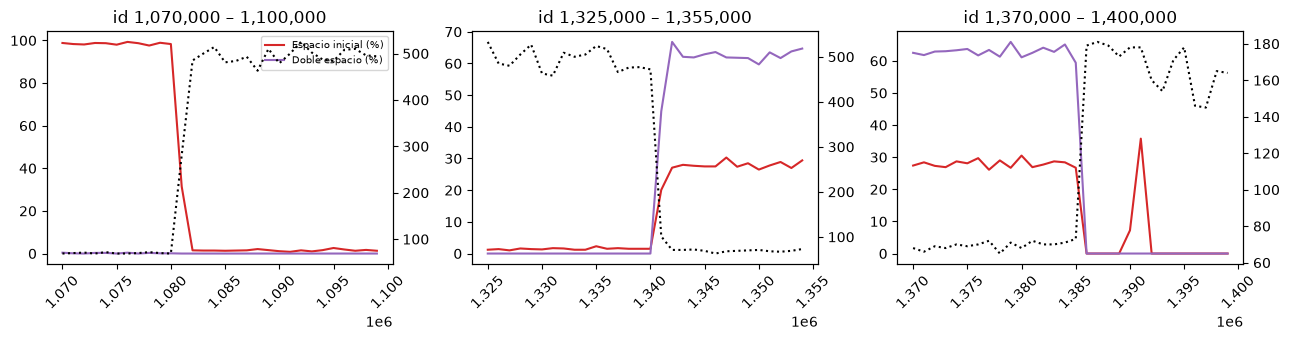

In [10]:
ZOOM = 1_000
t = F.col("text")
zona = (df.filter(F.col("source") == "ai")
    .withColumn("tramo", F.floor(F.col("id") / ZOOM) * ZOOM)
    .groupBy("tramo").agg(
        F.percentile_approx(F.size(F.split(F.trim(t), r"\s+")), 0.5).alias("mediana"),
        F.avg(t.rlike(r"^\s").cast("int")).alias("esp"),
        F.avg(t.rlike(r"[.!?]  [A-Z]").cast("int")).alias("dbl"),
    ).orderBy("tramo").collect())

ventanas = [(1_070_000, 1_100_000), (1_325_000, 1_355_000), (1_370_000, 1_400_000)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (a, b) in zip(axes, ventanas):
    z = [r for r in zona if a <= r["tramo"] < b]
    x = [r["tramo"] for r in z]
    ax.plot(x, [r["esp"] * 100 for r in z], label="Espacio inicial (%)", color="tab:red")
    ax.plot(x, [r["dbl"] * 100 for r in z], label="Doble espacio (%)", color="tab:purple")
    ax2 = ax.twinx()
    ax2.plot(x, [r["mediana"] for r in z], color="black", linestyle=":", label="Mediana palabras")
    ax.set_title(f"id {a:,} – {b:,}")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

El perfil general (tramos de 10.000 ids) mostraba tres límites dudosos entre bloques de IA. Para fijarlos con precisión se repite el análisis solo sobre los textos de IA, con tramos de **1.000 ids**, alrededor de cada límite. En cada panel se representan:
- **Espacio inicial (%)** (rojo): textos que empiezan con un espacio o salto de línea.
- **Doble espacio (%)** (morado): textos con dos espacios tras un punto.
- **Mediana de palabras** (línea negra punteada, eje derecho).

**Panel 1 (ids 1,070M – 1,100M): GPT-3 → GPT-2.** El espacio inicial cae del ~100 % al ~2 % y la mediana salta de ~100 a ~480 palabras. Las respuestas cortas de GPT-3 terminan y empiezan los textos largos de GPT-2. Límite: **1.081.500**.

**Panel 2 (ids 1,325M – 1,355M): GPT-2 → GPT-J.** Aparece de golpe el doble espacio (~60 %) y la mediana cae de ~480 a ~70 palabras. Empiezan las respuestas cortas de GPT-J, que tienen ese estilo de espaciado. Límite: **1.339.500**.

**Panel 3 (ids 1,370M – 1,400M): GPT-J → ChatGPT.** El doble espacio desaparece y la mediana sube de ~70 a ~170 palabras. Empiezan las respuestas de ChatGPT. Límite: **1.386.000**.

En los tres casos el cambio es brusco, lo que confirma que cada bloque procede de una fuente distinta.

***Conclusiones***
- El dataset no indica la fuente de cada texto, pero los `id` están ordenados: primero todos los humanos y después toda la IA.
- El perfil a lo largo del `id` muestra 8 bloques con longitud y artefactos muy distintos: el dataset se construyó concatenando fuentes en orden.
- Los límites se fijaron con un zoom de 1.000 ids, buscando dónde cambian bruscamente los patrones (margen de error ≈ ±1.000 ids, despreciable frente al tamaño de los bloques).
- Los tamaños de los bloques coinciden con la ficha del dataset (p. ej. GPT-2 258k frente a 260k, ChatGPT 32,7k frente a 32,5k) y los ejemplos confirman el género de cada uno.
- La ficha (que presenta su desglose como provisional) declara ~410k textos de IA, pero el dataset contiene 364k. La diferencia (~46k) es compatible con que uno de los dos conjuntos de GPT-3 declarados (44k) no se incluyera, aunque no es posible confirmarlo.
- La asignación es **inferida**: se usa solo para analizar resultados por fuente y **nunca como variable del modelo** (el `id` separa las clases al 100 %).

## 3. Longitud de los textos

***Percentiles por clase***

In [11]:
df_len = df.select(
    "source",
    F.length("text").alias("n_chars"),
    F.size(F.split(F.trim("text"), r"\s+")).alias("n_words"),
).cache()

df_len.groupBy("source").agg(
    F.percentile_approx("n_words", [0.05, 0.25, 0.5, 0.75, 0.95]).alias("palabras_p5_p25_p50_p75_p95"),
    F.percentile_approx("n_chars", [0.05, 0.25, 0.5, 0.75, 0.95]).alias("caracteres_p5_p25_p50_p75_p95"),
).show(truncate=False)

[Stage 46:===================================>                    (10 + 6) / 16]

+------+---------------------------+-----------------------------+
|source|palabras_p5_p25_p50_p75_p95|caracteres_p5_p25_p50_p75_p95|
+------+---------------------------+-----------------------------+
|human |[79, 174, 190, 394, 1289]  |[448, 988, 996, 2379, 8310]  |
|ai    |[34, 111, 305, 693, 854]   |[197, 638, 1776, 3981, 4922] |
+------+---------------------------+-----------------------------+



- Los textos de IA son más largos: mediana de 305 palabras frente a 190 en los humanos.
- Los textos humanos están concentrados en torno a ~1.000 caracteres: son los trozos de Reddit cortados al construir el dataset.
- Los textos humanos tienen una cola muy larga (ensayos y páginas web); los de IA tienen un techo cerca de las 850 palabras por el límite de generación de los modelos.
- **La longitud separa las clases por cómo se construyó el dataset, no por el estilo de escritura. Por eso hay que recortar todos los textos a una longitud fija**.

***Histograma de palabras***

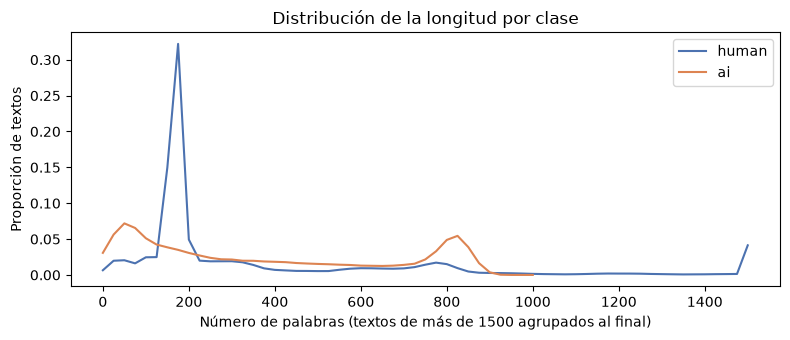

In [12]:
BIN = 25          # anchura de cada barra (palabras)
MAX = 1500        # cortamos la cola larga para que se vea bien

hist = (df_len
        .withColumn("bin", F.least(F.floor(F.col("n_words") / BIN) * BIN, F.lit(MAX)))
        .groupBy("source", "bin").count()
        .collect())

plt.figure(figsize=(8, 3.5))
for clase, color in [("human", "#4C72B0"), ("ai", "#DD8452")]:
    filas = sorted((r["bin"], r["count"]) for r in hist if r["source"] == clase)
    n = sum(c for _, c in filas)
    plt.plot([b for b, _ in filas], [c / n for _, c in filas], label=clase, color=color)
plt.xlabel("Número de palabras (textos de más de 1500 agrupados al final)")
plt.ylabel("Proporción de textos")
plt.title("Distribución de la longitud por clase")
plt.legend()
plt.tight_layout()
plt.show()

- **Pico humano en ~175 palabras** (un 32 % de los textos humanos): son los trozos de Reddit cortados a ~1.000 caracteres. No es una longitud natural, es un artefacto del dataset.
- **La IA tiene dos picos**:
  - ~50 palabras: respuestas cortas de asistentes (ChatGPT, GPT-J).
  - ~800 palabras: textos de GPT-2 que llegan al límite máximo de generación del modelo.
- **La IA nunca supera ~1.000 palabras**, mientras que los humanos tienen una cola larga (el repunte al final son los ensayos y páginas web de más de 1.500 palabras).
- Cada fuente deja su propia "huella" de longitud, así que un modelo podría acertar solo mirando la longitud. Hay que recortar todos los textos a una ventana fija de palabras.

## 4. Artefactos de formato por fuente
Se mide el porcentaje de textos de cada fuente que presentan marcas de formato ajenas a la escritura
(restos de la creación del dataset). Si un artefacto aparece solo en una clase, el modelo podría usarlo
como atajo en lugar de aprender diferencias reales de estilo.

In [13]:
t = F.col("text")
ARTEFACTOS = {
    "Empieza en minúscula":    t.rlike(r"^[a-z]"),
    "Empieza con espacio":     t.rlike(r"^\s"),
    "Comillas LaTeX ``":       t.contains("``"),
    "Apóstrofo separado":      t.rlike(r"\w [’'] \w"),
    "Puntuación con espacios": t.rlike(r"\w [.,!?;:] "),
    "Paréntesis con espacios": t.rlike(r"\( | \)"),
    "Doble espacio":           t.rlike(r"[.!?]  [A-Z]"),
    "Asteriscos (markdown)":   t.contains("*"),
    "Título '... Essay'":      F.split(t, "\n").getItem(0).rlike(r"Essay\s*$"),
}

ORDEN = ["human_ivypanda", "human_webtext", "human_hc3", "human_reddit_wp",
         "ai_gpt3", "ai_gpt2", "ai_gptj", "ai_chatgpt"]

tabla = (df_sub.groupBy("subsource")
         .agg(*[F.round(F.avg(c.cast("int")) * 100, 1).alias(n) for n, c in ARTEFACTOS.items()])
         .collect())
tabla = sorted(tabla, key=lambda r: ORDEN.index(r["subsource"]))

for r in tabla:
    print(r.asDict())

[Stage 52:====================================================>   (15 + 1) / 16]

{'subsource': 'human_ivypanda', 'Empieza en minúscula': 0.0, 'Empieza con espacio': 0.0, 'Comillas LaTeX ``': 0.0, 'Apóstrofo separado': 0.2, 'Puntuación con espacios': 70.0, 'Paréntesis con espacios': 8.7, 'Doble espacio': 0.7, 'Asteriscos (markdown)': 9.4, "Título '... Essay'": 55.9}
{'subsource': 'human_webtext', 'Empieza en minúscula': 2.1, 'Empieza con espacio': 0.0, 'Comillas LaTeX ``': 0.0, 'Apóstrofo separado': 0.2, 'Puntuación con espacios': 8.8, 'Paréntesis con espacios': 3.1, 'Doble espacio': 0.0, 'Asteriscos (markdown)': 4.7, "Título '... Essay'": 0.2}
{'subsource': 'human_hc3', 'Empieza en minúscula': 3.3, 'Empieza con espacio': 0.0, 'Comillas LaTeX ``': 0.0, 'Apóstrofo separado': 5.0, 'Puntuación con espacios': 84.8, 'Paréntesis con espacios': 30.9, 'Doble espacio': 1.9, 'Asteriscos (markdown)': 8.8, "Título '... Essay'": 0.0}
{'subsource': 'human_reddit_wp', 'Empieza en minúscula': 36.3, 'Empieza con espacio': 10.1, 'Comillas LaTeX ``': 52.4, 'Apóstrofo separado': 17.0, 

***Mapa de calor***

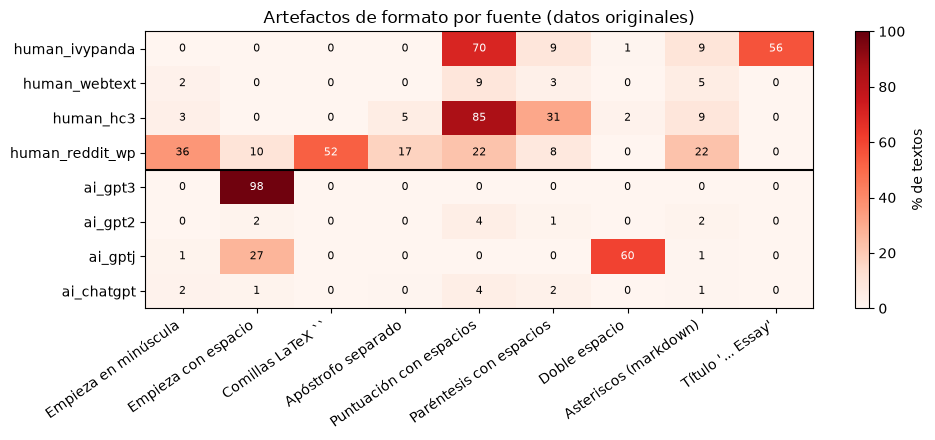

In [14]:
import numpy as np

nombres = list(ARTEFACTOS)
M = np.array([[r[n] for n in nombres] for r in tabla])

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(M, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(nombres)), nombres, rotation=35, ha="right")
ax.set_yticks(range(len(ORDEN)), ORDEN)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center",
                color="white" if M[i, j] > 50 else "black", fontsize=8)
ax.axhline(3.5, color="black", linewidth=1.5)        # separa humanos de IA
fig.colorbar(im, ax=ax, label="% de textos")
ax.set_title("Artefactos de formato por fuente (datos originales)")
plt.tight_layout()
plt.show()

**Conclusiones:**
- Cada fuente tiene artefactos de formato propios, introducidos al construir el dataset:
  - **Reddit**: comillas LaTeX (52 %), textos que empiezan en minúscula por el troceado (36 %) y asteriscos de markdown (22 %).
  - **HC3**: puntuación y paréntesis separados por espacios (85 % y 31 %), por haber sido tokenizado.
    - **IvyPanda**: título "… Essay" en la primera línea (56 %) y espacios antes de la puntuación (70 %), lo cual se explora en la siguiente celda.
  - **GPT-3**: casi todos los textos empiezan con un espacio o salto de línea (98 %).
  - **GPT-J**: doble espacio tras el punto (60 %).
- La mayoría de estos artefactos aparecen **solo en una clase**: las comillas LaTeX, los títulos y la puntuación separada son casi exclusivos de los textos humanos; el espacio inicial y el doble espacio, de la IA.
- Un modelo podría distinguir las clases detectando solo estas marcas, sin aprender nada sobre cómo escriben humanos e IA. **Es imprescindible eliminarlas antes de entrenar.**
- WebText, GPT-2 y ChatGPT son las fuentes más limpias. WebText y GPT-2, además, tienen perfiles muy parecidos: son un buen par para evaluar el modelo sin atajos.

In [15]:
(df_sub.filter((F.col("subsource") == "human_ivypanda") & t.rlike(r"\w [.,!?;:] "))
       .select(F.regexp_extract(t, r"(.{0,40}\w [.,!?;:] .{0,40})", 1).alias("contexto"))
       .show(10, truncate=False))

[Stage 57:====================================>                    (7 + 4) / 11]

+------------------------------------------------------------------------------------+
|contexto                                                                            |
+------------------------------------------------------------------------------------+
|ssian Troops Take Over Kharkiv,” Le Monde , on the other hand, read “La Russie A Env|
|Corporation . (2022). Entrepreneur.                                                 |
|How to become a medical office assistant . (2021). Eagle Gate College. Web.         |
|comes to the cinema on Back to the Future , they will find similarities between them|
|l of Racial and Ethnic Health Disparities , vol. 8, no. 4, 2021, pp. 863-869.       |
|broff 36). In the film Every Secret Thing , a complex emotional attachment between A|
|t an employee and then broke a glass door . CNN. Web.                               |
|e Contenders Must Be Inclusive to Compete . Los Angeles Times. 2020. Web.           |
| Garden Still Life with a Kitten to Ocean 

**Los espacios antes de la puntuación** aparecen tras los títulos de obras citadas: eran texto en cursiva en la web original y la conversión de HTML a texto dejó un espacio al eliminar el formato.



In [16]:
df_len.unpersist()

DataFrame[source: string, n_chars: int, n_words: int]